# Antenna Tilt — 2a: two sectors, best-server, and interference

Stages 1a/1b modelled one sector: SINR was simply SNR. Here a second sector transmits on the **same
resource at the same time**, so every location now receives two signals. New logic lives in
`telecomopt.network`; the single-sector physics (`telecomopt.rf`) is reused unchanged in each sector's
own frame.

**Layout (decision log D11).** Two sites facing each other, inter-site distance (ISD) 500 m: sector 1
at $(0,0)$ facing $+x$, sector 2 at $(500,0)$ facing $-x$. This is a *controlled* layout — chosen
because its symmetry gives analytic checks and one tilt can be varied against a fixed one — not a claim
about which layout couples most strongly.

**Assumptions that create interference** (it does not follow from a second antenna alone):
both sectors transmit simultaneously on the same resource; powers and noise refer to the same bandwidth
(per PRB, [E] Table I); the receiver decodes **one** serving sector and treats the other as noise;
association is the strongest received power, with no handover hysteresis, coordination or load
balancing. Shadowing is deferred (D06): every number here is deterministic, median-link.

**Physics.** With received powers $S_j(\mathbf x)=P\,g_j(\mathbf x;t_j)$ (linear) and noise $N$:
$$s(\mathbf x)=\arg\max_j S_j(\mathbf x),\qquad
\mathrm{SINR}(\mathbf x)=\frac{S_{s}}{\sum_{j\ne s}S_j+N},\qquad C=\log_2(1+\mathrm{SINR}).$$
With two sectors, $\mathrm{SINR}=S_{\max}/(S_{\min}+N)$.

Three quantities are kept **separate** throughout: the **received-power maps** (how strongly each sector
reaches a point), the **association map** (which sector is strongest) and the **SINR map** (how good the
chosen link is, given the other sector).

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from telecomopt.rf import (RFParams, to_db, elevation_angle_deg, elevation_gain_db,
                           azimuth_gain_db, pattern_gain_db, path_loss_db)
from telecomopt.network import Sector, to_sector_frame, sinr_field, field_maps

In [12]:
p = RFParams()                                   # [E] Table I constants
ISD = 500.0                                      # modelling choice (D11): half-ISD = 1b's d_max
sectors = [Sector(0.0, 0.0, 0.0), Sector(ISD, 0.0, 180.0)]
N_mw = 10 ** (p.n0_dbm / 10)
print(f"P = {p.p_dbm} dBm/PRB, N0 = {p.n0_dbm} dBm/PRB, h_bs = {p.bs_height} m, ISD = {ISD:.0f} m")

P = 29.0 dBm/PRB, N0 = -111.0 dBm/PRB, h_bs = 30.0 m, ISD = 500 m


## 1. Symmetric baseline: the midpoint at equal tilts

At $t_1=t_2=8^\circ$ the layout is mirror-symmetric, so at the midpoint $(250,0)$ the two received
powers are equal, $S_1=S_2=S$. Then
$$\mathrm{SINR}=\frac{S}{S+N}<1\quad\Rightarrow\quad \mathrm{SINR}_{\mathrm{dB}}<0,\qquad C<1\ \text{bps/Hz},$$
strictly, for any positive noise. Both only *approach* 0 dB and 1 bps/Hz when $S\gg N$.
More generally, $C\ge 1 \iff S_{\max}\ge S_{\min}+N$ — relevant because 1b's illustrative bar was
$\gamma=1$ bps/Hz (see OQ10).

In [13]:
mid = sinr_field(np.array([ISD / 2]), np.array([0.0]), sectors, [8.0, 8.0], params=p)
S1, S2 = mid["powers"][:, 0]
print(f"S1 = {to_db(S1):.2f} dBm, S2 = {to_db(S2):.2f} dBm, S/N = {to_db(S1 / N_mw):.1f} dB")
print(f"SINR = {to_db(mid['sinr'][0]):+.5f} dB  (analytic S/(S+N): {to_db(S1 / (S1 + N_mw)):+.5f} dB)")
print(f"SE   = {mid['se'][0]:.6f} bps/Hz  (< 1, strictly)")

S1 = -66.56 dBm, S2 = -66.56 dBm, S/N = 44.4 dB
SINR = -0.00016 dB  (analytic S/(S+N): -0.00016 dB)
SE   = 0.999974 bps/Hz  (< 1, strictly)


## 2. Mechanism at three locations: hold $t_2$, vary $t_1$

Hold $t_2=8^\circ$ and sweep $t_1$ over $2$–$14^\circ$ (a *model-exploration* range, not a specific
antenna's RET limits). Track, at a point near sector 1, the midpoint, and a point near sector 2: the two
received powers, which sector serves, and the resulting SINR.

**Analytic prediction at the midpoint.** Both sectors see the midpoint on boresight at the same distance,
so path loss and azimuth gain cancel and equal power means equal elevation gain. In the main lobe
(unclipped parabola) with depression angle $\beta=\arctan\big((h_{bs}-h_{ue})/250\big)$:
$$(\beta-t_1)^2=(\beta-8^\circ)^2\;\Rightarrow\; t_1=8^\circ\quad\text{or}\quad t_1=2\beta-8^\circ .$$
So the serving sector at the midpoint can change **twice** as $t_1$ rises: a sector's received power is
not monotone in its own tilt (it rises as the beam approaches $\beta$, then falls past it).

In [14]:
probes = {"near sector 1 (100 m)": 100.0, "midpoint (250 m)": 250.0, "near sector 2 (400 m)": 400.0}
t1s = np.arange(2.0, 14.01, 0.1)
px, py = np.array(list(probes.values())), np.zeros(len(probes))
sweep = [sinr_field(px, py, sectors, [t1, 8.0], params=p) for t1 in t1s]
S_db = np.array([to_db(f["powers"]) for f in sweep])          # (n_t1, 2 sectors, 3 probes)
sinr_db = np.array([to_db(f["sinr"]) for f in sweep])         # (n_t1, 3 probes)
serving = np.array([f["serving"] for f in sweep])          # (n_t1, 3 probes)
beta = np.degrees(np.arctan((p.bs_height - p.ue_height) / (ISD / 2)))
print(f"beta at the midpoint = {beta:.3f} deg  ->  predicted crossings t1 = 8 and {2 * beta - 8:.3f} deg")

beta at the midpoint = 6.504 deg  ->  predicted crossings t1 = 8 and 5.007 deg


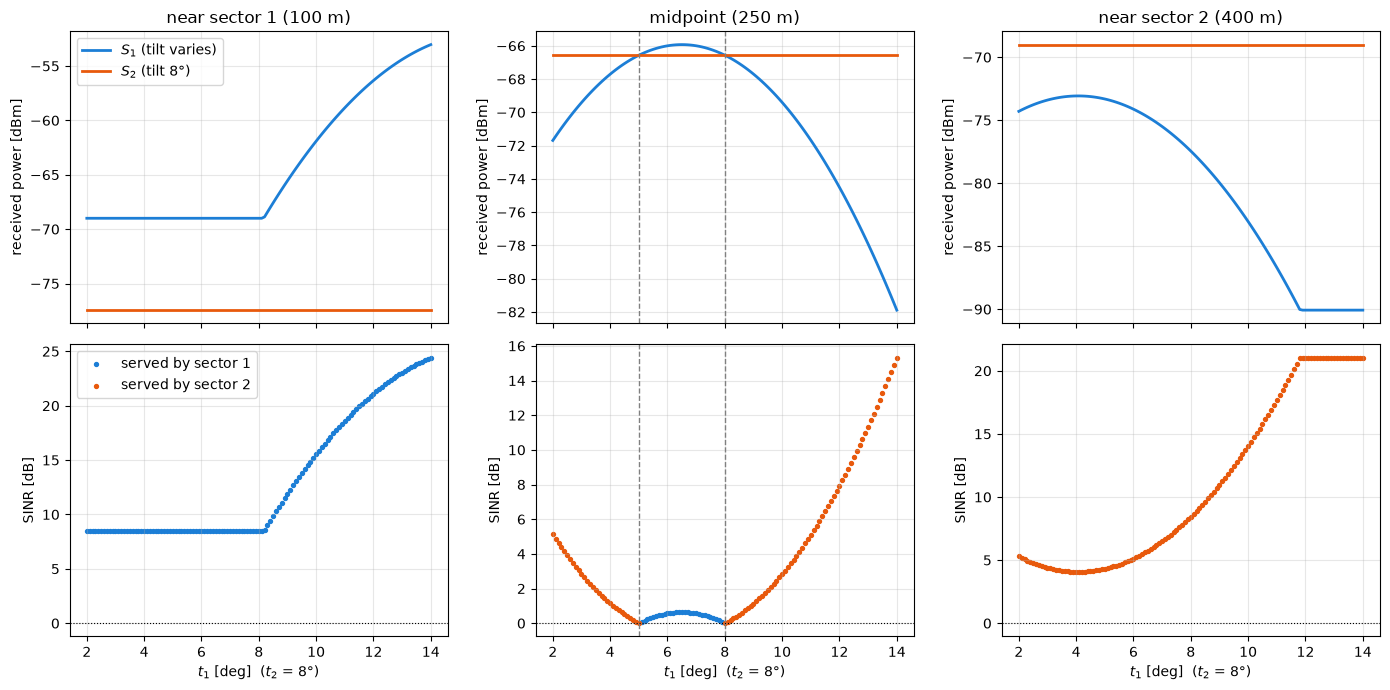

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for k, name in enumerate(probes):
    ax = axes[0, k]
    ax.plot(t1s, S_db[:, 0, k], color="#1c7ed6", lw=2, label="$S_1$ (tilt varies)")
    ax.plot(t1s, S_db[:, 1, k], color="#e8590c", lw=2, label="$S_2$ (tilt 8°)")
    ax.set_title(name); ax.set_ylabel("received power [dBm]"); ax.grid(alpha=0.3)
    ax = axes[1, k]
    for j, col in enumerate(["#1c7ed6", "#e8590c"]):
        m = serving[:, k] == j
        ax.scatter(t1s[m], sinr_db[m, k], s=8, color=col, label=f"served by sector {j + 1}")
    ax.axhline(0, color="k", lw=0.8, ls=":")
    ax.set_xlabel("$t_1$ [deg]  ($t_2$ = 8°)"); ax.set_ylabel("SINR [dB]"); ax.grid(alpha=0.3)
for ax in axes[:, 1]:
    for t in (8.0, 2 * beta - 8):
        ax.axvline(t, color="gray", lw=1, ls="--")
axes[0, 0].legend(); axes[1, 0].legend()
plt.tight_layout(); plt.show()

In [16]:
i_mid = list(probes).index("midpoint (250 m)")
flips = t1s[1:][np.diff(serving[:, i_mid]) != 0]
print("midpoint: serving sector changes at t1 ~", np.round(flips, 1), "deg (grid step 0.1 deg)")
for k, name in enumerate(probes):
    I_db = S_db[:, :, k].min(axis=1)                       # two sectors: interferer = the weaker one
    print(f"{name:24s} I/N over the sweep: {I_db.min() - p.n0_dbm:5.1f} to {I_db.max() - p.n0_dbm:5.1f} dB")

midpoint: serving sector changes at t1 ~ [5.1 8. ] deg (grid step 0.1 deg)
near sector 1 (100 m)    I/N over the sweep:  33.6 to  33.6 dB
midpoint (250 m)         I/N over the sweep:  29.1 to  44.4 dB
near sector 2 (400 m)    I/N over the sweep:  20.9 to  37.9 dB


In [17]:
w_floor = p.hpbw_el * np.sqrt(-p.sll_el / 12.0)    # |beta - t| at which Eq. 4 reaches SLL_el
for name, x in probes.items():
    b = elevation_angle_deg(x, p)                       # depression angle seen from sector 1
    print(f"{name:24s} beta from sector 1 = {b:6.3f} deg; sector 1 on its elevation floor for "
          f"t1 < {b - w_floor:6.3f} or t1 > {b + w_floor:6.3f} deg")

near sector 1 (100 m)    beta from sector 1 = 15.908 deg; sector 1 on its elevation floor for t1 <  8.171 or t1 > 23.644 deg
midpoint (250 m)         beta from sector 1 =  6.504 deg; sector 1 on its elevation floor for t1 < -1.233 or t1 > 14.240 deg
near sector 2 (400 m)    beta from sector 1 =  4.075 deg; sector 1 on its elevation floor for t1 < -3.661 or t1 > 11.812 deg


**Reading the sweep.** Each probe shows a different mechanism, and each is predicted by one angle: the
depression angle $\beta$ at which sector 1 sees the point. Sector 1's elevation gain is largest when its
tilt equals $\beta$, and sits on the constant $-17$ dB sidelobe floor once $|\beta-t_1|\ge
6.5\sqrt{17/12}\approx 7.74^\circ$ (printed above).

- **Near sector 1 (100 m), $\beta\approx15.9^\circ$.** Sector 1 serves at every tilt; the interferer (sector 2,
  fixed at $8^\circ$) is constant, so $I/N$ stays at 33.6 dB. $S_1$ and the SINR are flat until
  $t_1\approx 8.17^\circ$, where sector 1 leaves its elevation floor, then rise as the beam approaches
  $\beta$. The flat stretch is a property of the model's floor approximation — real antennas still vary
  in angle there (cf. L01).
- **Midpoint (250 m), $\beta\approx6.50^\circ$.** Sector 1 serves only between the two analytic crossings
  ($5.007^\circ$ and $8^\circ$; the labels change at $5.1^\circ$ and $8.0^\circ$ on the $0.1^\circ$ grid). The
  serving *label* jumps, but link quality varies continuously: SINR has a minimum of $\approx 0$ dB at each
  tie, and at an exact tie either label gives the same SINR (the lowest-index tie rule is bookkeeping only).
- **Near sector 2 (400 m), $\beta\approx4.08^\circ$.** Sector 2 serves at every tilt, so $t_1$ changes only
  **how strongly sector 1 interferes**. The SINR is lowest at $t_1\approx\beta$ (sector 1 aimed straight at
  this user), rises as sector 1 tilts past it, and is flat from $t_1\approx11.8^\circ$, where this point
  falls onto sector 1's elevation floor.

So, in this model, whether more downtilt at one sector helps or hurts a neighbouring sector's user depends
on where the tilt starts relative to that user's angle: below $\beta$ it **hurts** (the beam moves onto the
user), above $\beta$ it **helps** (the beam moves away), and past the floor edge it does **nothing** — the
last regime is again a consequence of the floor approximation. This is the coupling a joint (Stage 2b)
objective must handle; "more downtilt reduces interference" is not true in general here.

**Interference-limited?** The regime is read from $I/N$ (interference over noise), not from high SNR
alone. The $I/N$ printed above applies to these three points; the map below checks it over the region.

## 3. From points to maps

**Map region (modelling choice).** The rectangle between the sites, $x\in[0,500]$ m,
$y\in[-250,250]$ m, with points closer than $d_{\min}=35$ m to either mast masked (D09). This is a
*visualization* region for 2a; the evaluation region and demand for the 2b objective are decided there.
Best-server partitions this one fixed region between the sectors — it does not decide which points are
evaluated.

In [18]:
gx, gy = np.linspace(0.0, ISD, 101), np.linspace(-250.0, 250.0, 101)
X, Y = np.meshgrid(gx, gy)
base = field_maps(X, Y, sectors, [8.0, 8.0], d_min=35.0, params=p)   # d_min: D09 near-tower floor

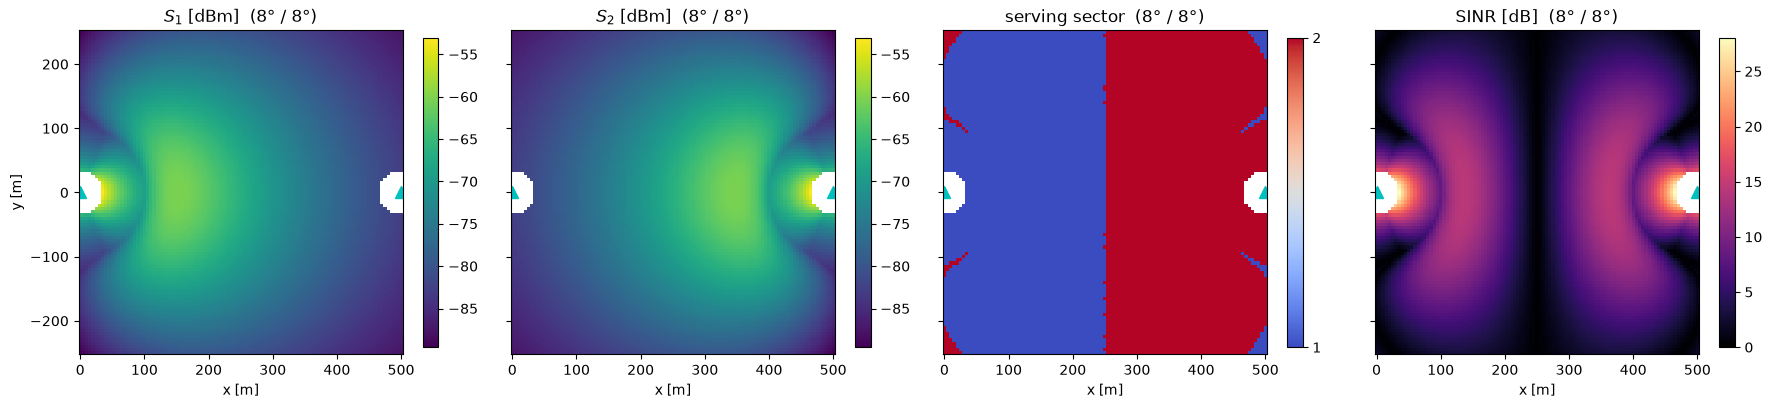

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
panels = [("$S_1$ [dBm]", base["power_dbm"][0], "viridis"), ("$S_2$ [dBm]", base["power_dbm"][1], "viridis"),
          ("serving sector", base["serving"] + 1, "coolwarm"), ("SINR [dB]", base["sinr_db"], "magma")]
for ax, (title, Z, cmap) in zip(axes, panels):
    im = ax.pcolormesh(gx, gy, Z, cmap=cmap, shading="auto")
    ax.plot([0, ISD], [0, 0], "c^", ms=9); ax.set_aspect("equal"); ax.set_title(title + "  (8° / 8°)")
    ax.set_xlabel("x [m]"); cb = fig.colorbar(im, ax=ax, shrink=0.8)
    if Z is panels[2][1]:
        cb.set_ticks([1, 2])
axes[0].set_ylabel("y [m]")
plt.tight_layout(); plt.show()

In [20]:
I_over_N = base["power_dbm"].min(axis=0) - p.n0_dbm       # two sectors: I = the weaker power
v = I_over_N[base["valid"]]
print(f"I/N over the valid map at 8/8: min {v.min():.1f} dB, median {np.median(v):.1f} dB; "
      f"share of points with I/N > 10 dB: {np.mean(v > 10):.1%}")

I/N over the valid map at 8/8: min 21.4 dB, median 31.8 dB; share of points with I/N > 10 dB: 100.0%


In this configuration the interference exceeds the noise at **every** valid grid point: the minimum
$I/N$ is about 21 dB (interference ≈ 140 × noise) and the median about 32 dB. At $8^\circ/8^\circ$ the system
is interference-limited over the whole mapped region, not just at the three probes — for this region,
these tilts and this grid.

## 4. The association boundary moves with $t_1$ — and is not the coverage boundary

Same maps for $t_1\in\{5^\circ, 8^\circ, 12^\circ\}$ with $t_2=8^\circ$. The equal-power line (the white
contour) says only that neither sector dominates there; whether service there is *acceptable* is a
separate question read from the SINR map.

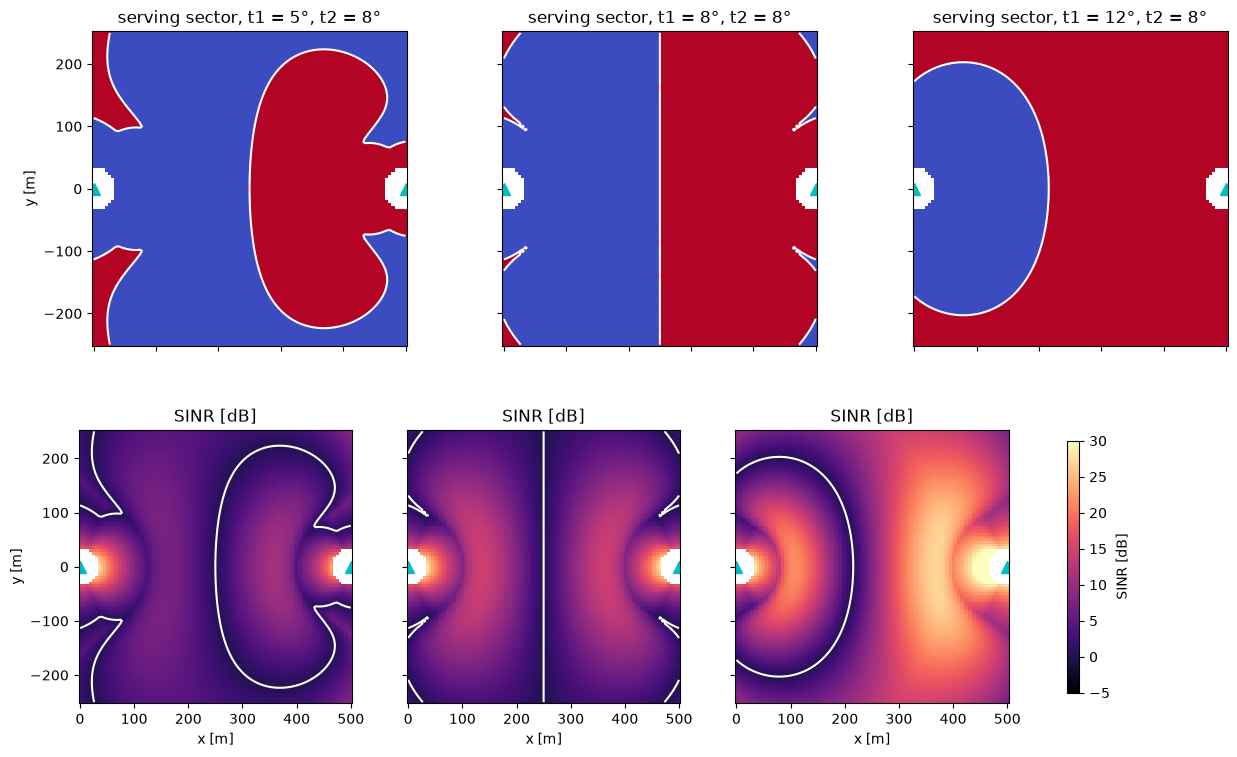

In [21]:
configs = [5.0, 8.0, 12.0]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for c, t1 in enumerate(configs):
    m = base if t1 == 8.0 else field_maps(X, Y, sectors, [t1, 8.0], d_min=35.0, params=p)
    axes[0, c].pcolormesh(gx, gy, m["serving"] + 1, cmap="coolwarm", shading="auto")
    im = axes[1, c].pcolormesh(gx, gy, m["sinr_db"], cmap="magma", vmin=-5, vmax=30, shading="auto")
    for r in (0, 1):
        axes[r, c].contour(gx, gy, m["power_dbm"][0] - m["power_dbm"][1], levels=[0.0], colors="w", linewidths=1.5)
        axes[r, c].plot([0, ISD], [0, 0], "c^", ms=9); axes[r, c].set_aspect("equal")
    axes[0, c].set_title(f"serving sector, t1 = {t1:g}°, t2 = 8°"); axes[1, c].set_title("SINR [dB]")
    axes[1, c].set_xlabel("x [m]")
for r in (0, 1):
    axes[r, 0].set_ylabel("y [m]")
fig.colorbar(im, ax=axes[1, :], shrink=0.8, label="SINR [dB]")
plt.show()

**The line between the sites is not the whole boundary.** At $8^\circ/8^\circ$ the power maps mirror each
other and the main equal-power boundary is the bisector $x=250$ m. But the association maps also show
small **off-axis regions where the farther sector serves** — visible at $8^\circ/8^\circ$ beside each mast,
and much larger at $5^\circ/8^\circ$. A boundary measured along the line between the sites therefore cannot
stand in for the 2-D association map. One point inside such a region, decomposed into its pattern and
path-loss terms:

In [22]:
print("points on sector 1's half served by sector 2 at 8/8:",
      int(np.sum((base["serving"] == 1) & (X < ISD / 2))))
pt_x, pt_y = np.array([35.0]), np.array([95.0])
for j, s in enumerate(sectors):
    d, a = (v[0] for v in to_sector_frame(pt_x, pt_y, s)); b = elevation_angle_deg(d, p)
    A = pattern_gain_db(b, a, 8.0, 0.0, p)
    print(f"sector {j + 1}: d = {d:3.0f} m, az = {a:+5.1f} deg, G_az = {azimuth_gain_db(a, p):5.1f}, "
          f"G_el = {elevation_gain_db(b, 8.0, p):5.1f}, A = {A:5.1f} dB, PL = {path_loss_db(d, p):5.1f} dB, "
          f"S = {p.p_dbm + p.g0_dbi + A - path_loss_db(d, p):5.1f} dBm")

points on sector 1's half served by sector 2 at 8/8: 84
sector 1: d = 101 m, az = +69.8 deg, G_az = -13.8, G_el = -16.9, A = -30.0 dB, PL =  99.2 dB, S = -82.2 dBm
sector 2: d = 475 m, az = -11.5 deg, G_az =  -0.4, G_el =  -5.9, A =  -6.3 dB, PL = 122.7 dB, S = -82.0 dBm


At $(35, 95)$ m sector 1 is only ~100 m away, but it sees the point about $70^\circ$ off boresight **and**
well below its beam, so the azimuth and elevation terms are weak *together*: their sum falls to the
overall pattern floor $\mathrm{SLL}_0=-30$ dB. Sector 2 sees the same point nearly on boresight, and its
~24 dB pattern advantage outweighs its ~23.5 dB extra path loss. The effect comes from the **combined**
2-D pattern ([E] Eq. 5), not from either term alone.

## 5. What carries into 2b

- Changing one tilt can change **which** sector serves a location (midpoint) or only **how good** its link
  is while the serving sector stays the same (100 m and 400 m). Both mechanisms are now visible.
- The per-point SE field is SINR-based and depends on **both** tilts. Stage 2b feeds it into the unchanged
  1b aggregation (`weighted_mean`, `weighted_percentile`, `served_fraction`) with a demand field over one
  fixed region.
- **Served fraction stays a hypothesis.** The white contour marks $S_1=S_2$, whereas failing the
  1 bps/Hz bar needs $|S_1-S_2|<N$ in linear power. Near the midpoint that strip is only millimetres wide
  (computed below), so counting failed points on a 5 m map grid would overstate its area by orders of
  magnitude. These maps establish the association mechanism; they do not measure a demand-weighted
  outage fraction (OQ10).
- Uncertainty (shadowing, D06) is still pending: every map here is a single deterministic median-link
  field.

In [23]:
xs = np.linspace(ISD / 2 - 0.01, ISD / 2 + 0.01, 20001)     # 1 um steps across the midpoint
line = sinr_field(xs, np.zeros_like(xs), sectors, [8.0, 8.0], params=p)
print(f"width of the SE < 1 bps/Hz strip on the line between the sites: "
      f"{np.sum(line['se'] < 1.0) * (xs[1] - xs[0]) * 1e3:.1f} mm (map grid step: {gx[1] - gx[0]:.0f} m)")

width of the SE < 1 bps/Hz strip on the line between the sites: 1.9 mm (map grid step: 5 m)
